In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

df_clean = df.copy()

df_clean['TotalCharges'] = pd.to_numeric(
    df_clean['TotalCharges'].str.strip(),
    errors='coerce'
)

print("Libraries loaded successfully!")
print("Dataset shape:", df_clean.shape)
print("Missing TotalCharges:", df_clean['TotalCharges'].isna().sum())

Libraries loaded successfully!
Dataset shape: (7043, 21)
Missing TotalCharges: 11


In [2]:
contract_churn = pd.crosstab(
    df_clean['Contract'],
    df_clean['Churn'],
    normalize='index'
) * 100

print(contract_churn.round(2))

Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


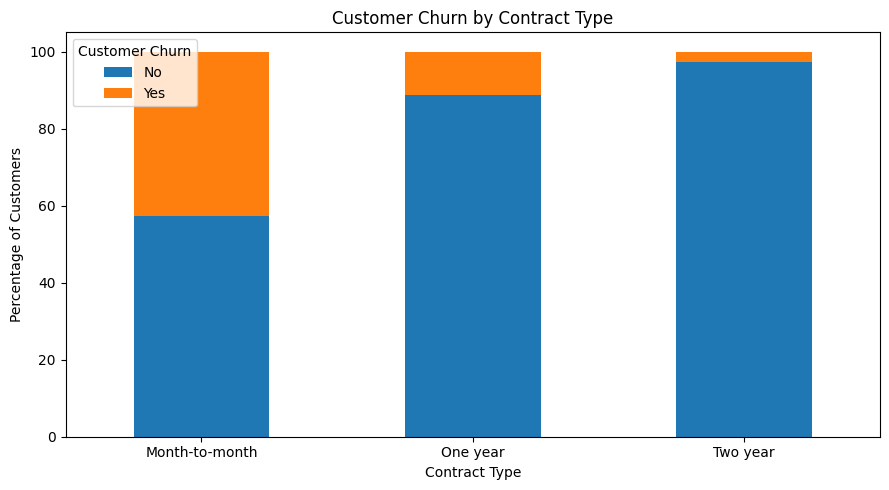

In [3]:
contract_churn.plot(
    kind='bar',
    figsize=(9, 5),
    stacked=True
)

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Percentage of Customers')
plt.xticks(rotation=0)
plt.legend(title='Customer Churn')
plt.tight_layout()
plt.show()

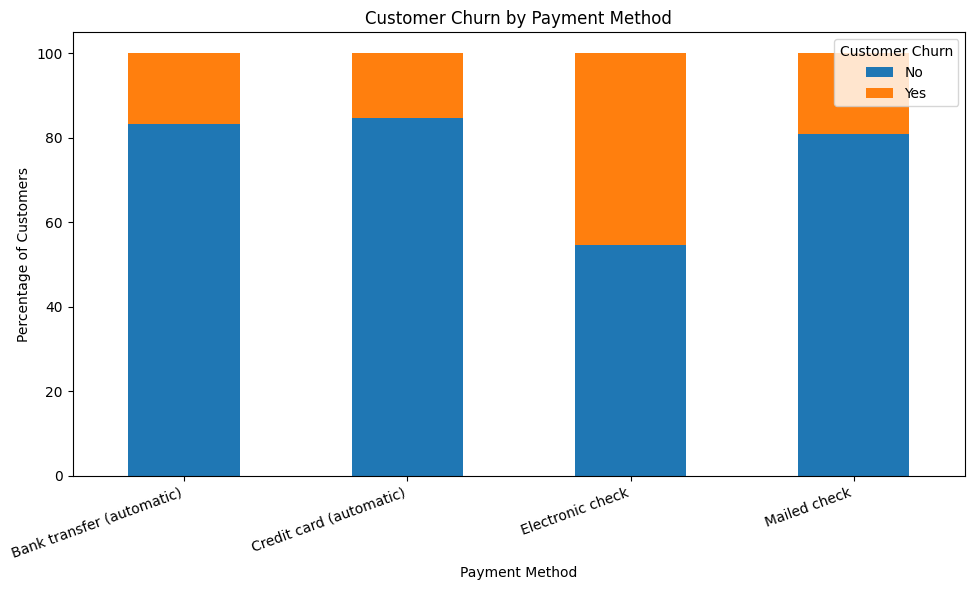

In [4]:
payment_churn = pd.crosstab(
    df_clean['PaymentMethod'],
    df_clean['Churn'],
    normalize='index'
) * 100

payment_churn.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Customer Churn by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Percentage of Customers')
plt.xticks(rotation=20, ha='right')
plt.legend(title='Customer Churn')
plt.tight_layout()
plt.show()

In [5]:
tenure_churn = df_clean.groupby('Churn')['tenure'].agg(
    ['mean', 'median']
)

print(tenure_churn.round(2))

        mean  median
Churn               
No     37.57    38.0
Yes    17.98    10.0


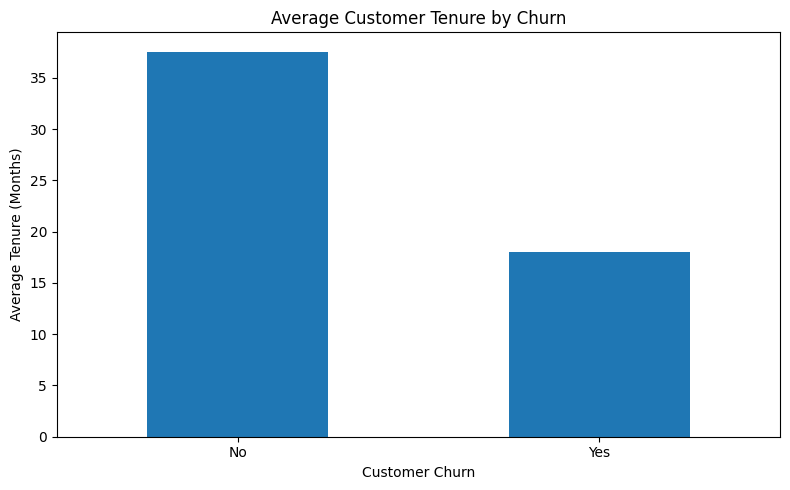

In [6]:
tenure_churn['mean'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Average Customer Tenure by Churn')
plt.xlabel('Customer Churn')
plt.ylabel('Average Tenure (Months)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
monthly_charges = df_clean.groupby('Churn')['MonthlyCharges'].agg(
    ['mean', 'median']
)

print(monthly_charges.round(2))

        mean  median
Churn               
No     61.27   64.43
Yes    74.44   79.65


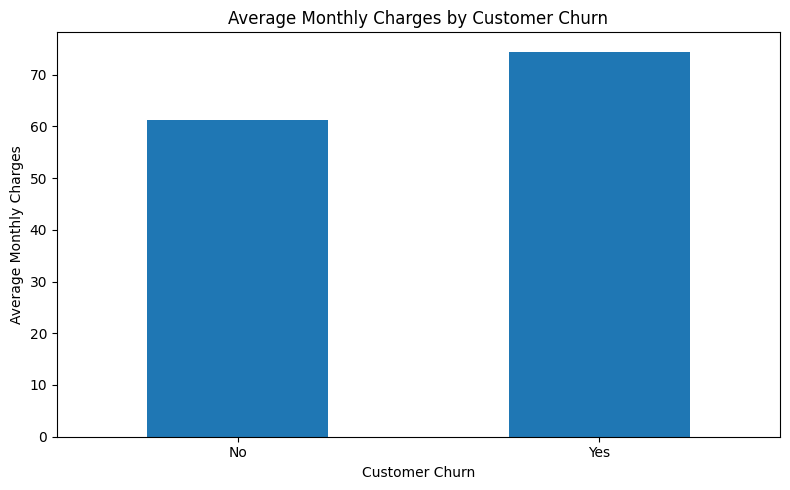

In [8]:
monthly_charges['mean'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Average Monthly Charges by Customer Churn')
plt.xlabel('Customer Churn')
plt.ylabel('Average Monthly Charges')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [9]:
internet_churn = pd.crosstab(
    df_clean['InternetService'],
    df_clean['Churn'],
    normalize='index'
) * 100

print(internet_churn.round(2))

Churn               No    Yes
InternetService              
DSL              81.04  18.96
Fiber optic      58.11  41.89
No               92.60   7.40


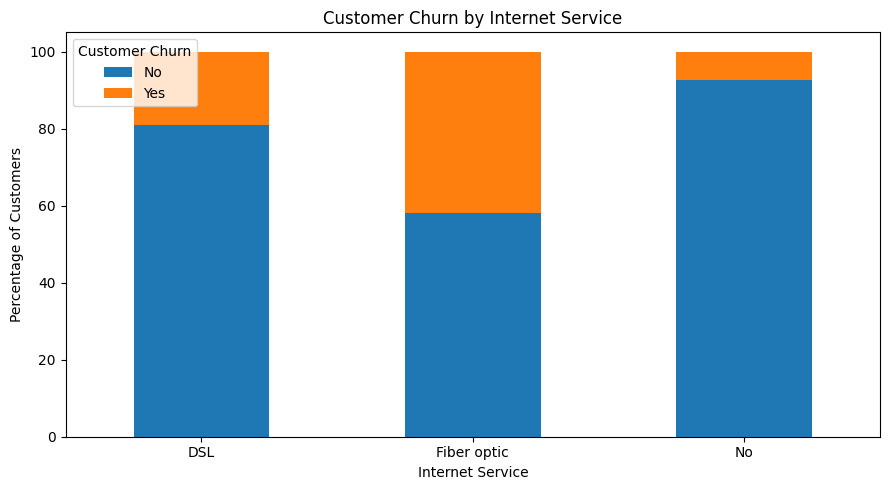

In [10]:
internet_churn.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5)
)

plt.title('Customer Churn by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Percentage of Customers')
plt.xticks(rotation=0)
plt.legend(title='Customer Churn')
plt.tight_layout()
plt.show()

In [11]:
security_churn = pd.crosstab(
    df_clean['OnlineSecurity'],
    df_clean['Churn'],
    normalize='index'
) * 100

print(security_churn.round(2))

Churn                   No    Yes
OnlineSecurity                   
No                   58.23  41.77
No internet service  92.60   7.40
Yes                  85.39  14.61


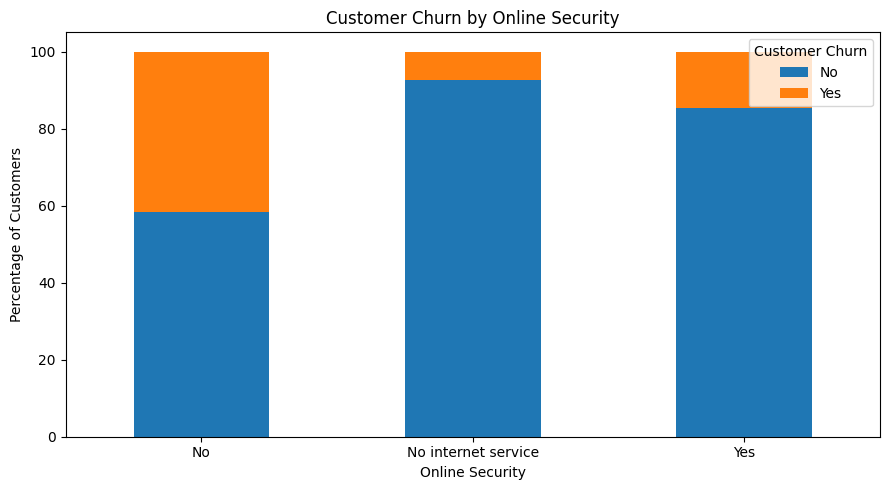

In [12]:
security_churn.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5)
)

plt.title('Customer Churn by Online Security')
plt.xlabel('Online Security')
plt.ylabel('Percentage of Customers')
plt.xticks(rotation=0)
plt.legend(title='Customer Churn')
plt.tight_layout()
plt.show()

In [13]:
support_churn = pd.crosstab(
    df_clean['TechSupport'],
    df_clean['Churn'],
    normalize='index'
) * 100

print(support_churn.round(2))

Churn                   No    Yes
TechSupport                      
No                   58.36  41.64
No internet service  92.60   7.40
Yes                  84.83  15.17


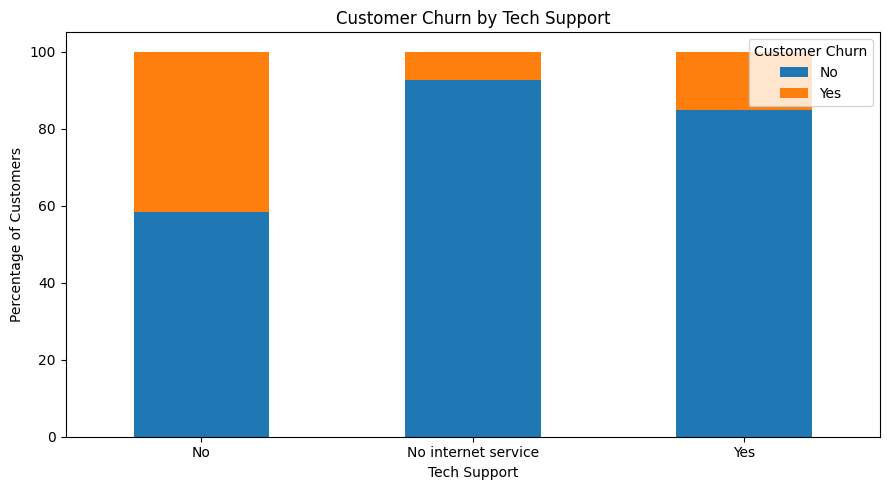

In [14]:
support_churn.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5)
)

plt.title('Customer Churn by Tech Support')
plt.xlabel('Tech Support')
plt.ylabel('Percentage of Customers')
plt.xticks(rotation=0)
plt.legend(title='Customer Churn')
plt.tight_layout()
plt.show()

In [15]:
contract_charges = df_clean.groupby('Contract')['MonthlyCharges'].agg(
    ['mean', 'median']
)

print(contract_charges.round(2))

                 mean  median
Contract                     
Month-to-month  66.40   73.25
One year        65.05   68.75
Two year        60.77   64.35


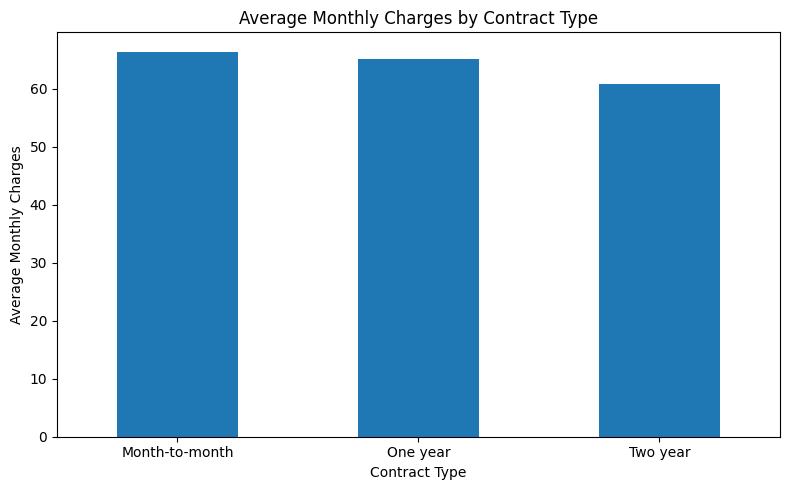

In [16]:
contract_charges['mean'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Average Monthly Charges by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Average Monthly Charges')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [17]:
billing_churn = pd.crosstab(
    df_clean['PaperlessBilling'],
    df_clean['Churn'],
    normalize='index'
) * 100

print(billing_churn.round(2))

Churn                No    Yes
PaperlessBilling              
No                83.67  16.33
Yes               66.43  33.57


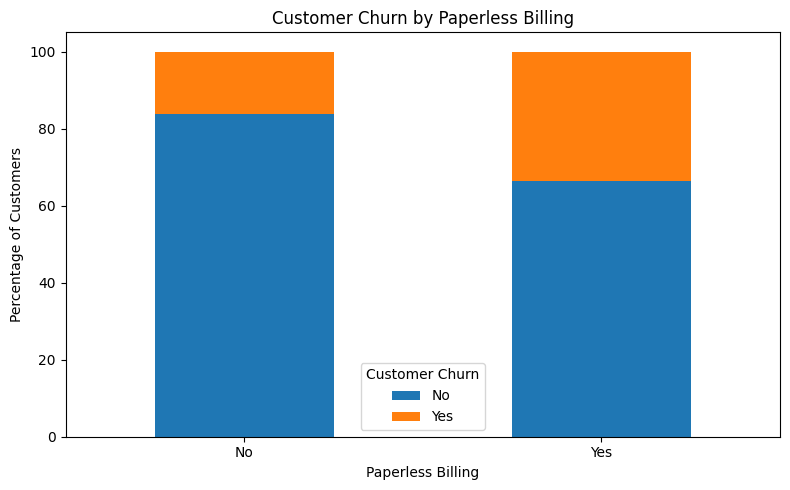

In [18]:
billing_churn.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5)
)

plt.title('Customer Churn by Paperless Billing')
plt.xlabel('Paperless Billing')
plt.ylabel('Percentage of Customers')
plt.xticks(rotation=0)
plt.legend(title='Customer Churn')
plt.tight_layout()
plt.show()

In [19]:
senior_churn = pd.crosstab(
    df_clean['SeniorCitizen'],
    df_clean['Churn'],
    normalize='index'
) * 100

senior_churn.index = ['Non-Senior Citizens', 'Senior Citizens']

print(senior_churn.round(2))

Churn                   No    Yes
Non-Senior Citizens  76.39  23.61
Senior Citizens      58.32  41.68


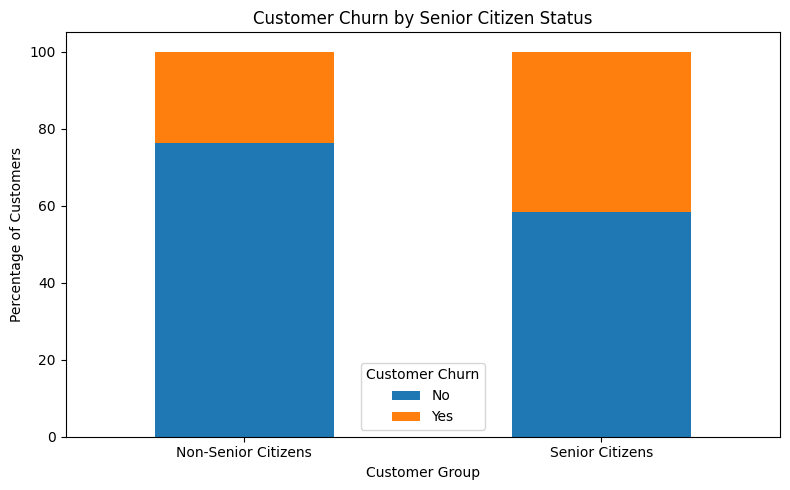

In [20]:
senior_churn.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5)
)

plt.title('Customer Churn by Senior Citizen Status')
plt.xlabel('Customer Group')
plt.ylabel('Percentage of Customers')
plt.xticks(rotation=0)
plt.legend(title='Customer Churn')
plt.tight_layout()
plt.show()

In [21]:
gender_churn = pd.crosstab(
    df_clean['gender'],
    df_clean['Churn'],
    normalize='index'
) * 100

print(gender_churn.round(2))

Churn      No    Yes
gender              
Female  73.08  26.92
Male    73.84  26.16


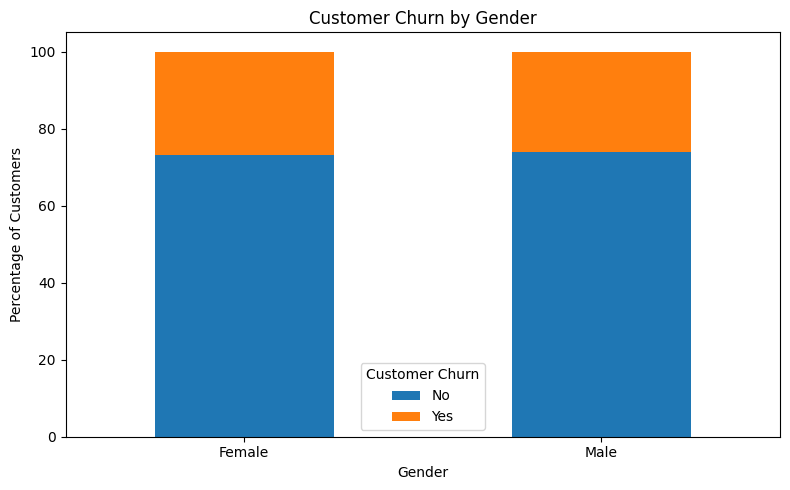

In [22]:
gender_churn.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5)
)

plt.title('Customer Churn by Gender')
plt.xlabel('Gender')
plt.ylabel('Percentage of Customers')
plt.xticks(rotation=0)
plt.legend(title='Customer Churn')
plt.tight_layout()
plt.show()

In [23]:
total_charges = df_clean.groupby('Churn')['TotalCharges'].agg(
    ['mean', 'median']
)

print(total_charges.round(2))

          mean   median
Churn                  
No     2555.34  1683.60
Yes    1531.80   703.55


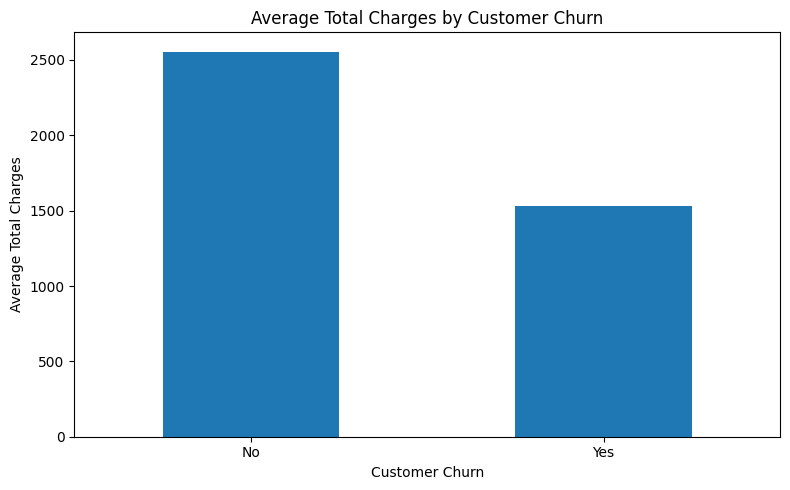

In [24]:
total_charges['mean'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Average Total Charges by Customer Churn')
plt.xlabel('Customer Churn')
plt.ylabel('Average Total Charges')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [25]:
internet_charges = df_clean.groupby('InternetService')['MonthlyCharges'].agg(
    ['mean', 'median']
)

print(internet_charges.round(2))

                  mean  median
InternetService               
DSL              58.10   56.15
Fiber optic      91.50   91.68
No               21.08   20.15


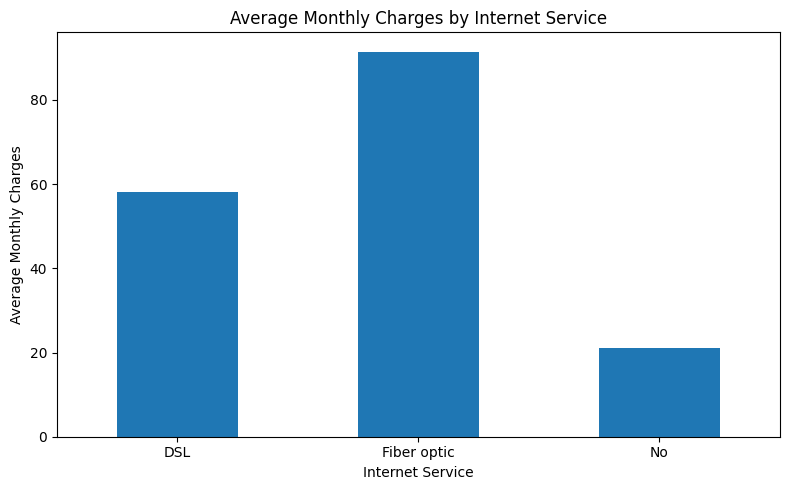

In [26]:
internet_charges['mean'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Average Monthly Charges by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Average Monthly Charges')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [27]:
df_clean['TenureGroup'] = pd.cut(
    df_clean['tenure'],
    bins=[-1, 12, 24, 48, 72],
    labels=['0-12 months', '13-24 months',
            '25-48 months', '49-72 months']
)

tenure_group_churn = pd.crosstab(
    df_clean['TenureGroup'],
    df_clean['Churn'],
    normalize='index'
) * 100

print(tenure_group_churn.round(2))

Churn            No    Yes
TenureGroup               
0-12 months   52.56  47.44
13-24 months  71.29  28.71
25-48 months  79.61  20.39
49-72 months  90.49   9.51


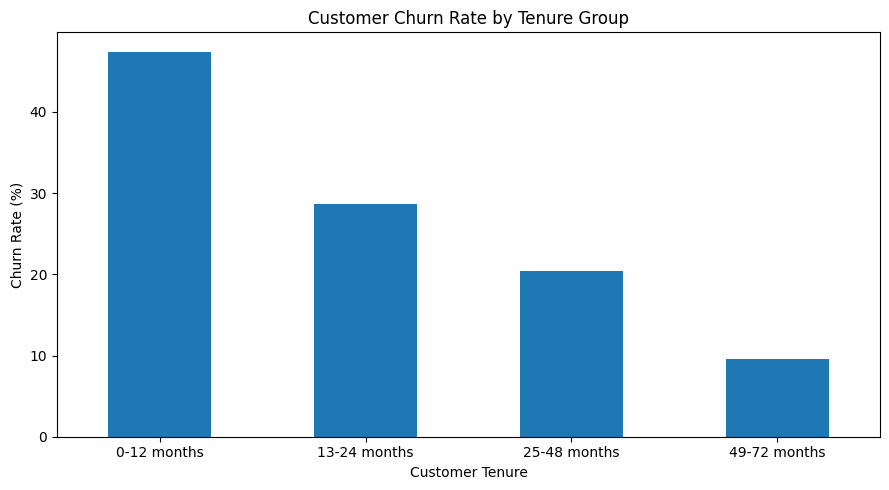

In [28]:
tenure_group_churn['Yes'].plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Customer Churn Rate by Tenure Group')
plt.xlabel('Customer Tenure')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [31]:
df_clean['Churn_encoded'] = df_clean['Churn'].map({
    'No': 0,
    'Yes': 1
})

In [32]:
correlation = df_clean[
    ['tenure', 'MonthlyCharges', 'TotalCharges',
     'SeniorCitizen', 'Churn_encoded']
].corr()

print(
    correlation['Churn_encoded']
    .sort_values(ascending=False)
    .round(3)
)

Churn_encoded     1.000
MonthlyCharges    0.193
SeniorCitizen     0.151
TotalCharges     -0.199
tenure           -0.352
Name: Churn_encoded, dtype: float64


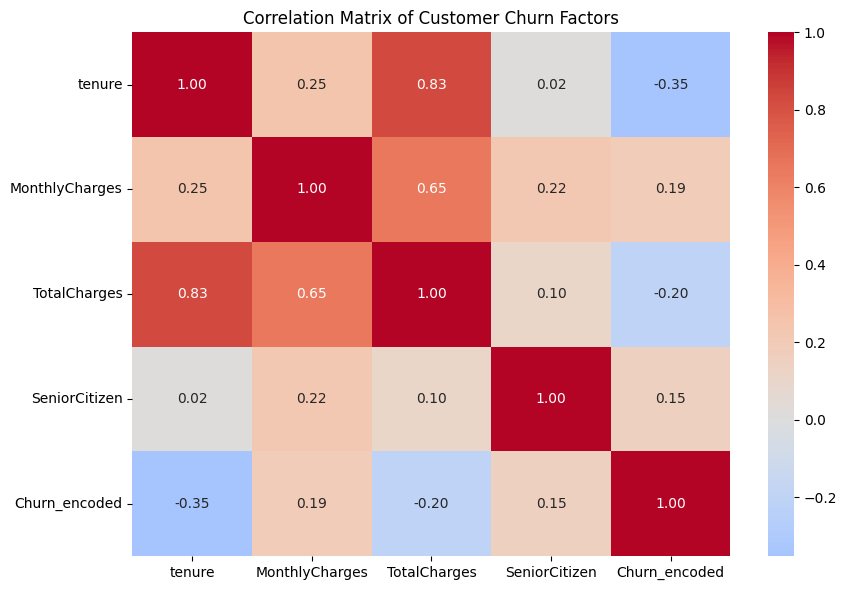

In [33]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Correlation Matrix of Customer Churn Factors')
plt.tight_layout()
plt.show()

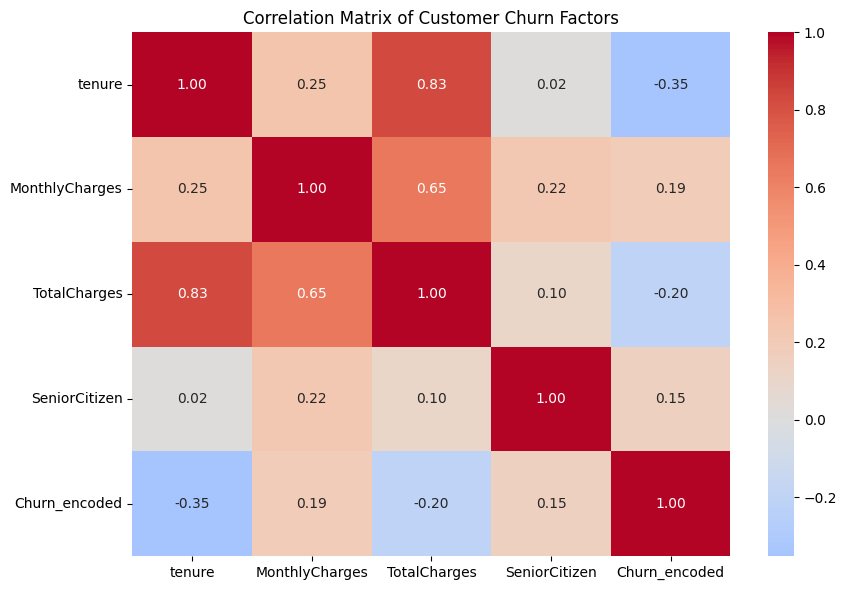

In [34]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Correlation Matrix of Customer Churn Factors')
plt.tight_layout()
plt.show()

In [35]:
print("Duplicate rows:", df_clean.duplicated().sum())

print("\nMissing values in each column:")
print(df_clean.isnull().sum())

Duplicate rows: 0

Missing values in each column:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
TenureGroup          0
Churn_encoded        0
dtype: int64


In [36]:
df_clean[df_clean['TotalCharges'].isna()][
    ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [37]:
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(0)

print("Missing TotalCharges after cleaning:",
      df_clean['TotalCharges'].isna().sum())

Missing TotalCharges after cleaning: 0


In [38]:
print("Final dataset shape:", df_clean.shape)

print("\nFinal missing values:",
      df_clean.isnull().sum().sum())

print("Final duplicate rows:",
      df_clean.duplicated().sum())

print("\nFirst 5 records:")
display(df_clean.head())

Final dataset shape: (7043, 23)

Final missing values: 0
Final duplicate rows: 0

First 5 records:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureGroup,Churn_encoded
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0-12 months,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.50,No,25-48 months,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0-12 months,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,25-48 months,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0-12 months,1
